**CELL 1 — Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

**CELL 2 - Load dataset**

In [ ]:
path = "/content/data.csv"

df = pd.read_csv(path)

print("Shape:", df.shape)
df.head()

Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**CELL 3 - Understand the dataset**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


**CELL 4 - Check column names**

In [ ]:
print(df.columns.tolist())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


**CELL 5 — Remove unnecessary columns**

In [ ]:
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

print(df.shape)

(569, 31)


**CELL 6 — Check missing values**

In [ ]:
print(df.isnull().sum().sort_values(ascending=False))

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


**CELL 7 — Check duplicate rows**

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**CELL 8 — Check target variable**

In [ ]:
print(df["diagnosis"].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


In [ ]:
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

print(df["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


**CELL 9 — Target distribution**

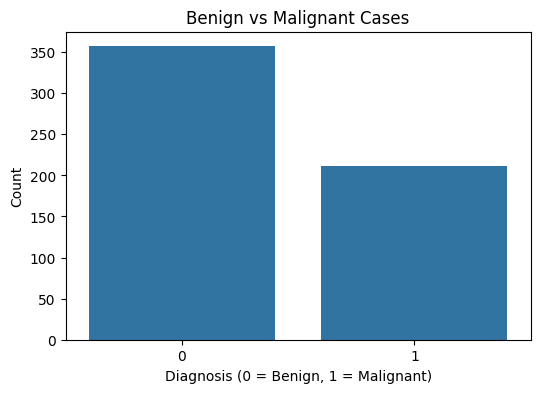

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x=df["diagnosis"])

plt.title("Benign vs Malignant Cases")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Count")
plt.show()

In [ ]:
print(df["diagnosis"].value_counts(normalize=True) * 100)

diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


**CELL 10 — Separate features and target**

In [ ]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


**CELL 11 — List all features**

In [ ]:
for i, col in enumerate(X.columns, 1):
    print(i, col)

1 radius_mean
2 texture_mean
3 perimeter_mean
4 area_mean
5 smoothness_mean
6 compactness_mean
7 concavity_mean
8 concave points_mean
9 symmetry_mean
10 fractal_dimension_mean
11 radius_se
12 texture_se
13 perimeter_se
14 area_se
15 smoothness_se
16 compactness_se
17 concavity_se
18 concave points_se
19 symmetry_se
20 fractal_dimension_se
21 radius_worst
22 texture_worst
23 perimeter_worst
24 area_worst
25 smoothness_worst
26 compactness_worst
27 concavity_worst
28 concave points_worst
29 symmetry_worst
30 fractal_dimension_worst


**CELL 12 — Understand feature groups**

In [ ]:
mean_features = [c for c in X.columns if c.endswith("_mean")]
se_features = [c for c in X.columns if c.endswith("_se")]
worst_features = [c for c in X.columns if c.endswith("_worst")]

print("Mean features:", len(mean_features))
print("SE features:", len(se_features))
print("Worst features:", len(worst_features))

Mean features: 10
SE features: 10
Worst features: 10


**CELL 13 — Feature distributions**

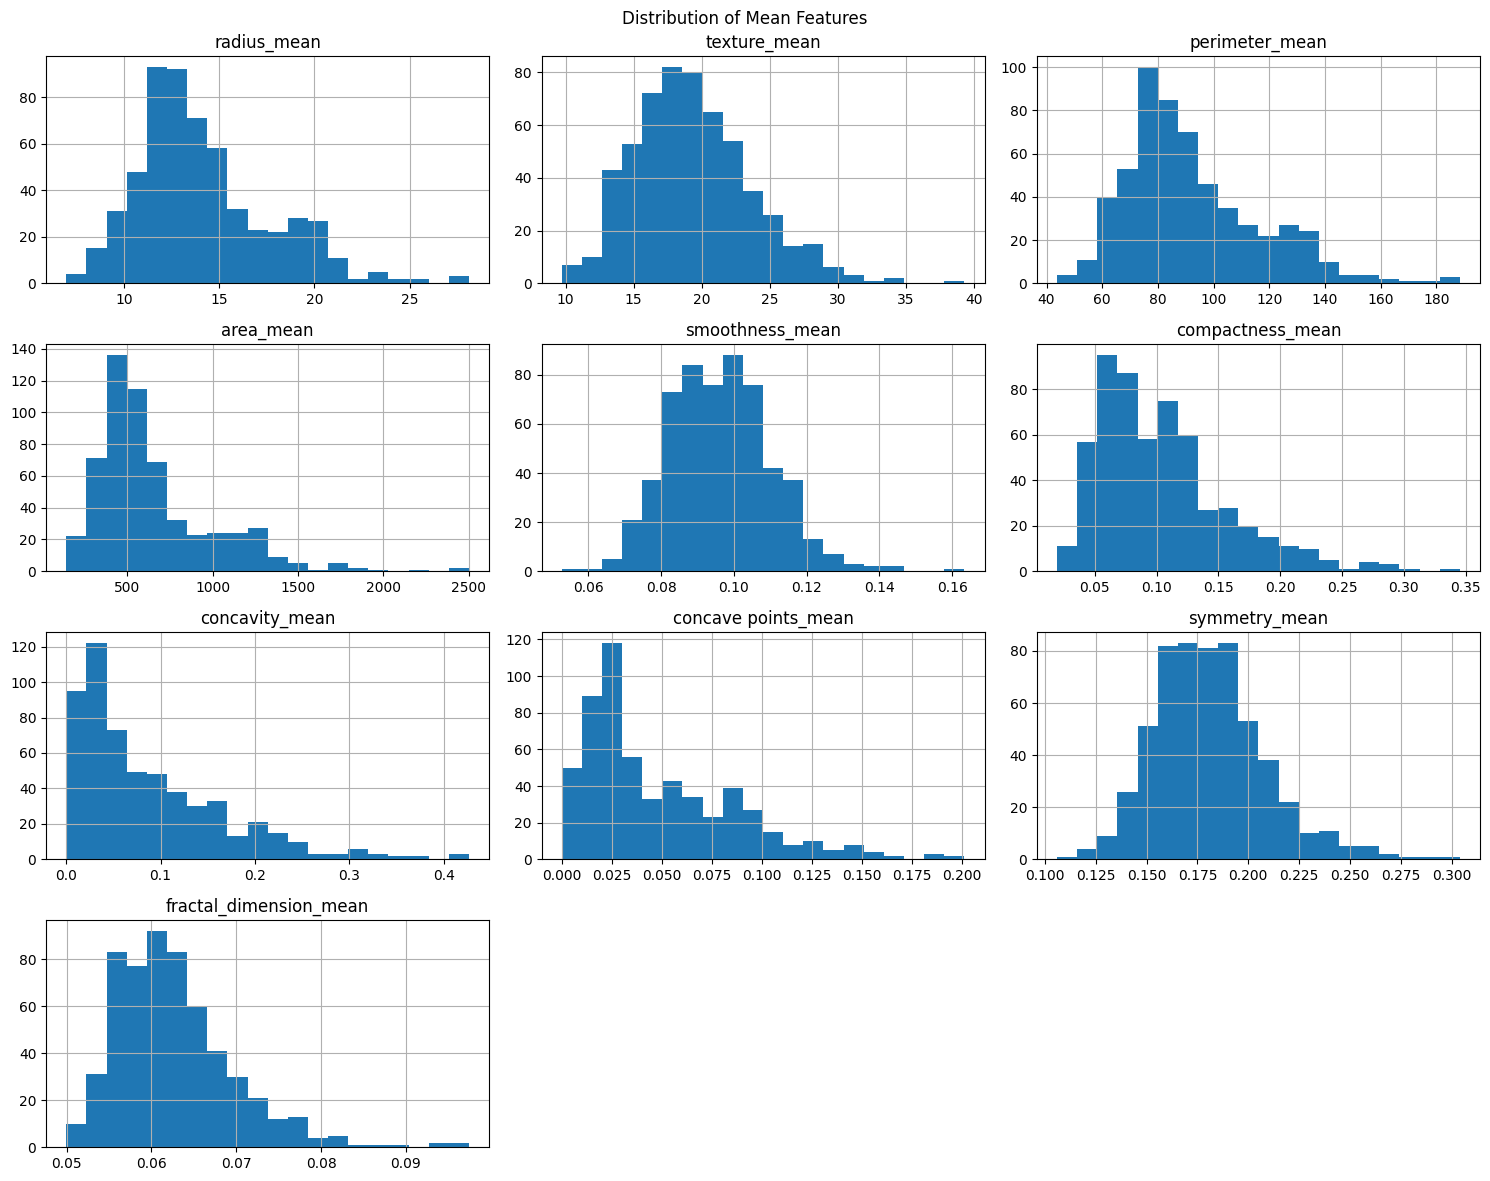

In [ ]:
features = [
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave points_mean",
    "symmetry_mean", "fractal_dimension_mean"
]

df[features].hist(figsize=(15,12), bins=20)
plt.suptitle("Distribution of Mean Features")
plt.tight_layout()
plt.show()

**CELL 14 — Compare features by diagnosis**

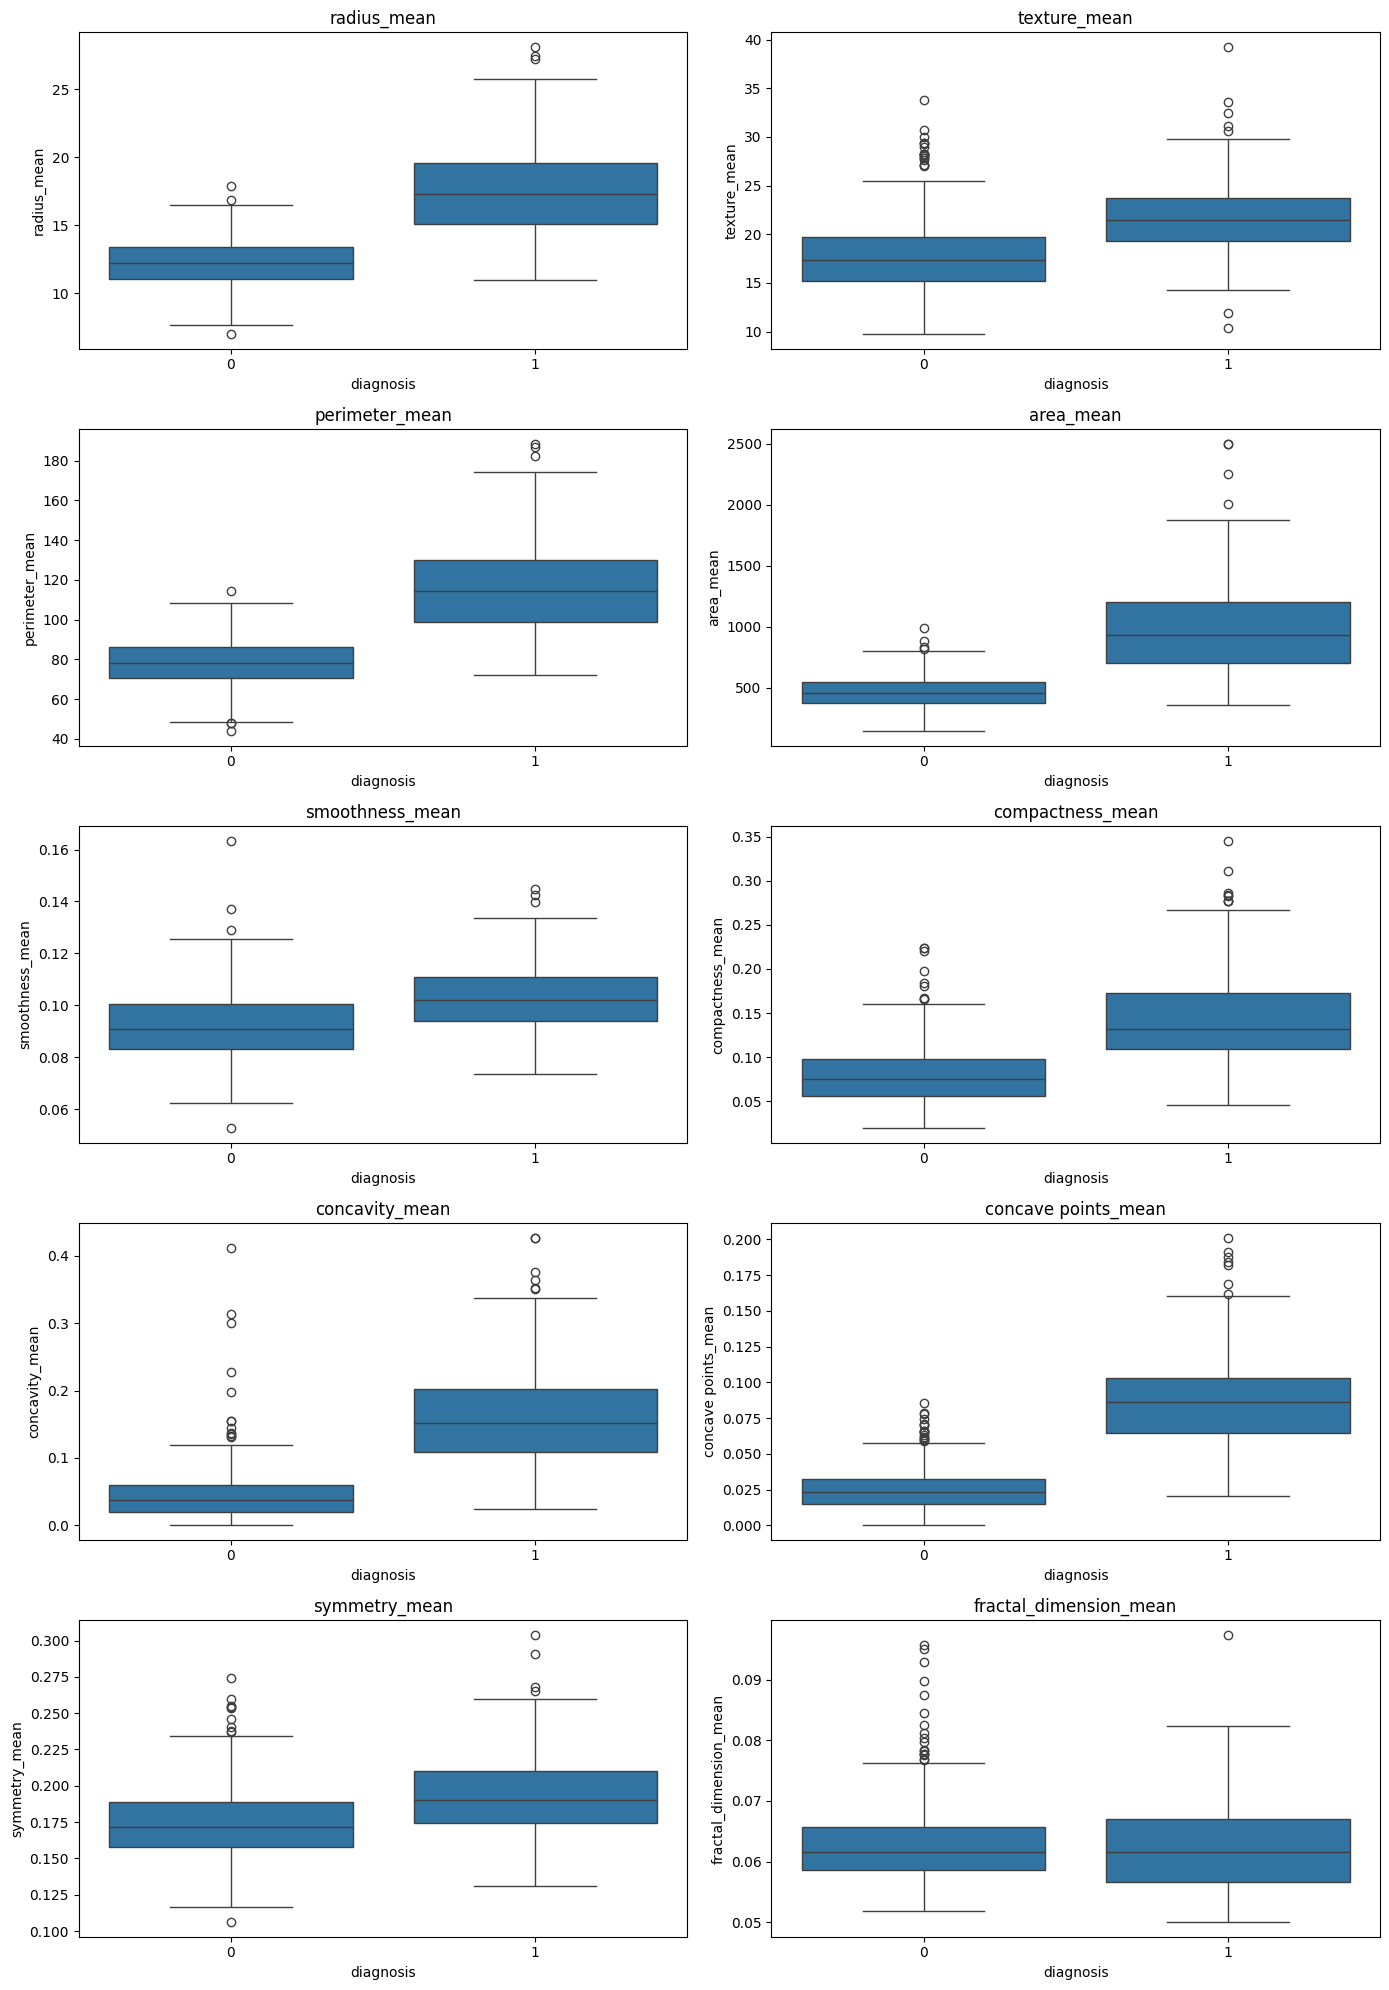

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for ax, feature in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="diagnosis", y=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

**CELL 15 — Correlation heatmap**

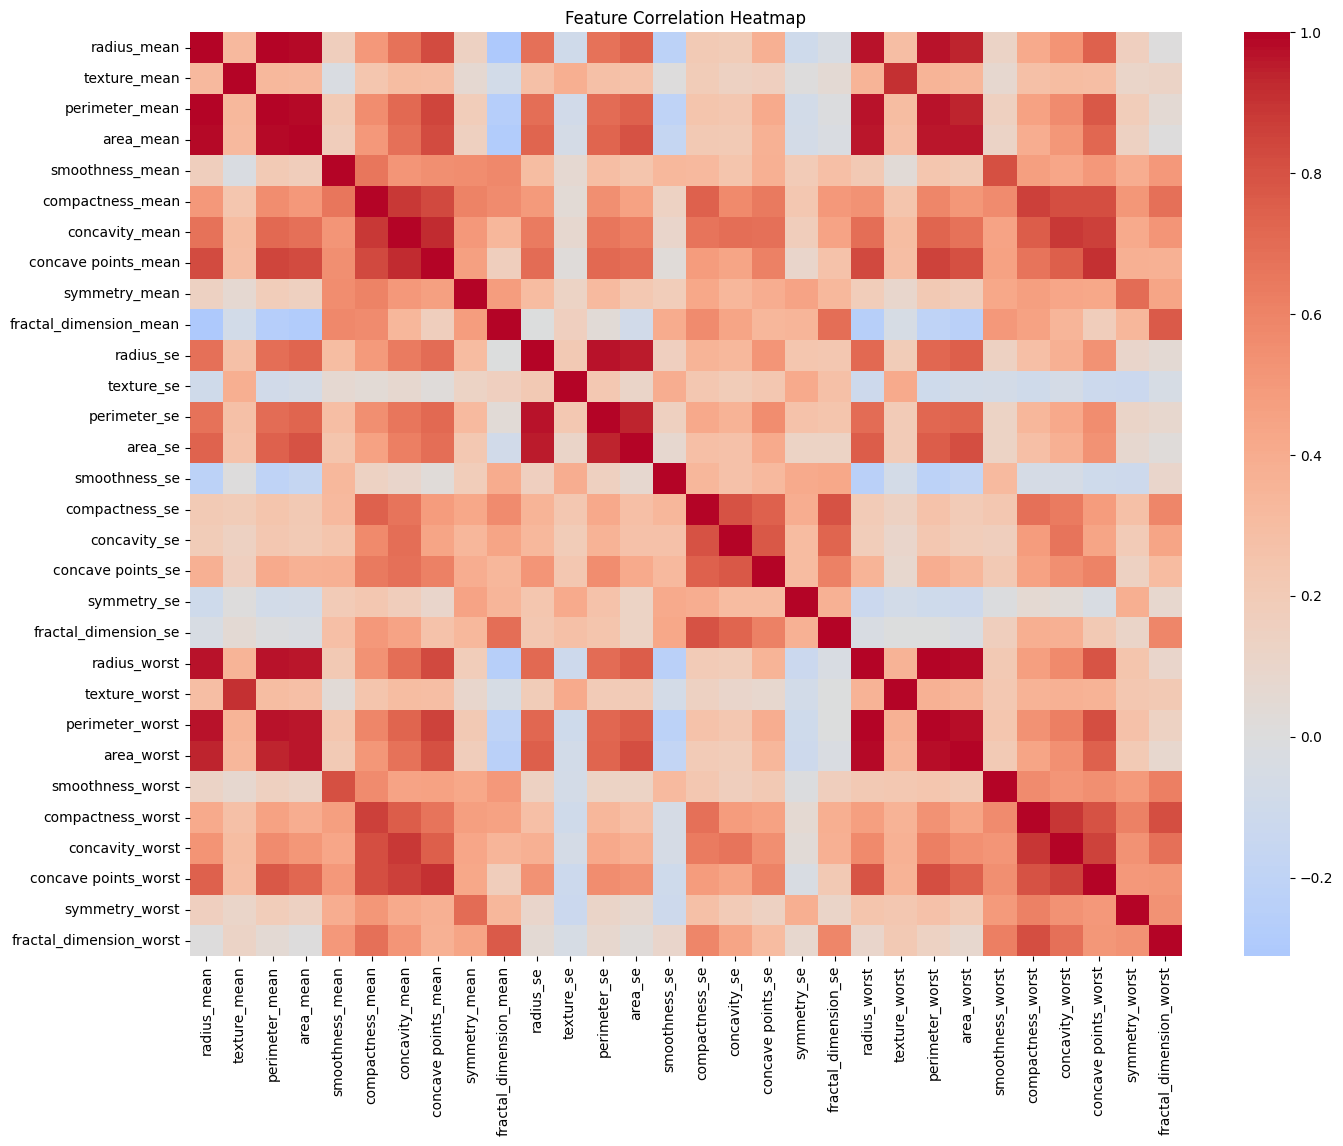

In [ ]:
plt.figure(figsize=(16,12))

corr = X.corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

**CELL 16 — Find highly correlated features**

In [ ]:
corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = [
    column for column in upper.columns
    if any(upper[column] > 0.90)
]

print("Highly correlated features:")
print(high_corr)

Highly correlated features:
['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst']


**CELL 17 — Check outliers**

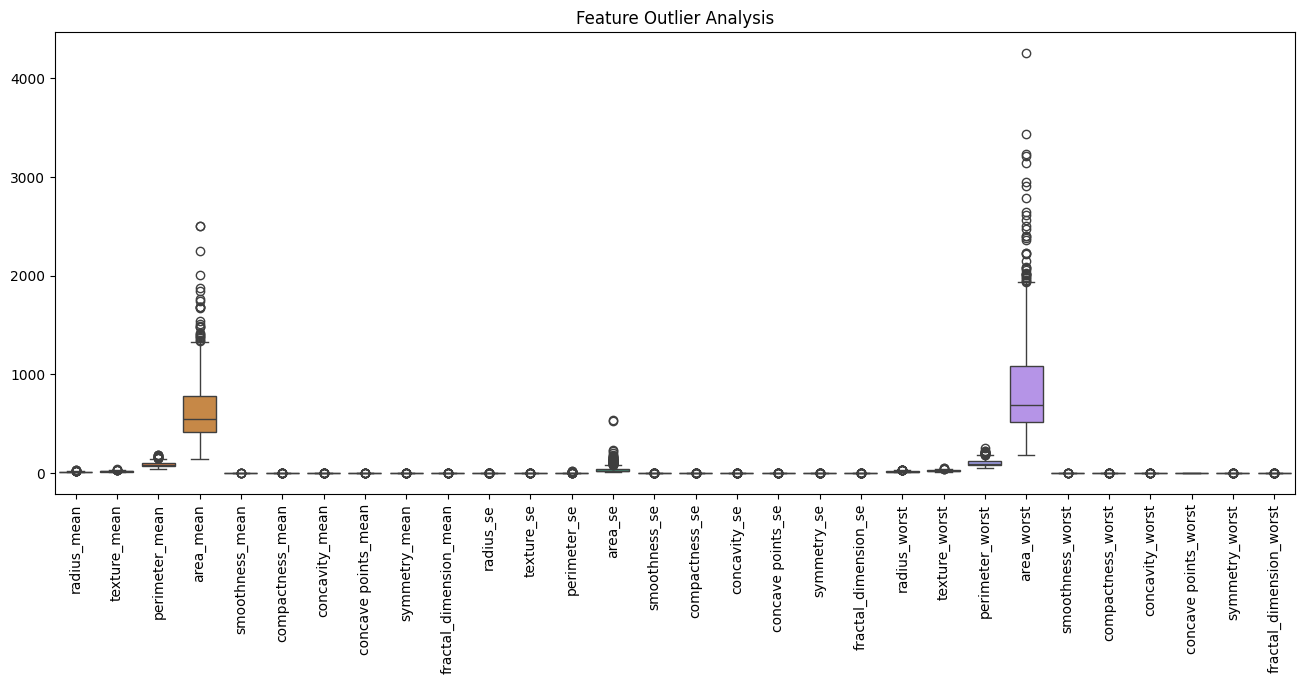

In [ ]:
plt.figure(figsize=(16,6))

sns.boxplot(data=X)

plt.xticks(rotation=90)
plt.title("Feature Outlier Analysis")
plt.show()

**CELL 18 — Train-test split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (455, 30)
Testing : (114, 30)


**CELL 19 — Basic Decision Tree**

In [ ]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:, 1]

**CELL 20 — Decision Tree evaluation**

In [ ]:
print("Decision Tree")
print("----------------")

print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))
print("ROC-AUC  :", roc_auc_score(y_test, dt_prob))
print("PR-AUC   :", average_precision_score(y_test, dt_prob))

Decision Tree
----------------
Accuracy : 0.9298245614035088
Precision: 0.9047619047619048
Recall   : 0.9047619047619048
F1 Score : 0.9047619047619048
ROC-AUC  : 0.9246031746031745
PR-AUC   : 0.8536818236066357


**CELL 21 — Decision Tree confusion matrix**

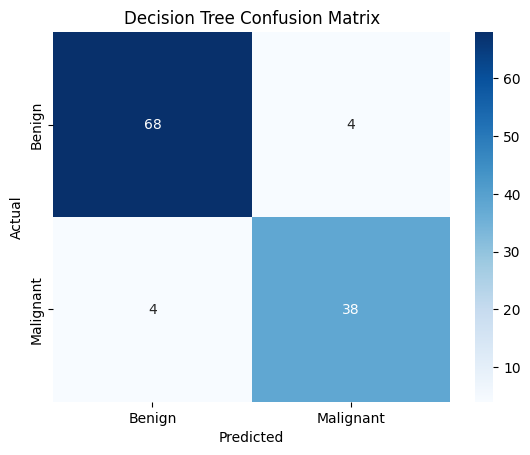

In [ ]:
cm = confusion_matrix(y_test, dt_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

**CELL 22 — Random Forest**

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

**CELL 23 — Random Forest evaluation**

In [ ]:
print("Random Forest")
print("----------------")

print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))
print("PR-AUC   :", average_precision_score(y_test, rf_prob))

Random Forest
----------------
Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.9047619047619048
F1 Score : 0.95
ROC-AUC  : 0.9970238095238095
PR-AUC   : 0.9952258653750137


**CELL 24 — Random Forest confusion matrix**

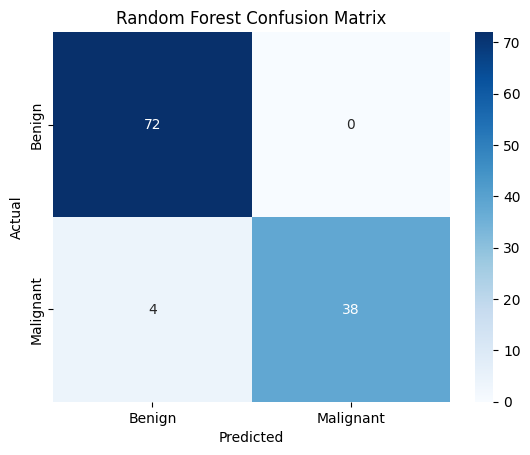

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

**CELL 25 — Classification report**

In [ ]:
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



**CELL 26 — Tune Decision Tree**

In [ ]:
dt_params = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best parameters:")
print(dt_grid.best_params_)
print("Best CV ROC-AUC:", dt_grid.best_score_)

Best parameters:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV ROC-AUC: 0.962280701754386


**CELL 27 — Tuned Decision Tree**

In [ ]:
best_dt = dt_grid.best_estimator_

best_dt_pred = best_dt.predict(X_test)
best_dt_prob = best_dt.predict_proba(X_test)[:, 1]

print("Tuned Decision Tree")
print("-------------------")
print("Accuracy :", accuracy_score(y_test, best_dt_pred))
print("Precision:", precision_score(y_test, best_dt_pred))
print("Recall   :", recall_score(y_test, best_dt_pred))
print("F1 Score :", f1_score(y_test, best_dt_pred))
print("ROC-AUC  :", roc_auc_score(y_test, best_dt_prob))
print("PR-AUC   :", average_precision_score(y_test, best_dt_prob))

Tuned Decision Tree
-------------------
Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.9047619047619048
F1 Score : 0.95
ROC-AUC  : 0.9730489417989417
PR-AUC   : 0.9665988696797425


**CELL 28 — Tune Random Forest**

In [ ]:
rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    rf_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:")
print(rf_grid.best_params_)

print("Best CV ROC-AUC:",
      rf_grid.best_score_)

Best parameters:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV ROC-AUC: 0.9915376676986583


**CELL 29 — Final Random Forest**

In [ ]:
best_rf = rf_grid.best_estimator_

best_rf_pred = best_rf.predict(X_test)
best_rf_prob = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("-------------------")
print("Accuracy :", accuracy_score(y_test, best_rf_pred))
print("Precision:", precision_score(y_test, best_rf_pred))
print("Recall   :", recall_score(y_test, best_rf_pred))
print("F1 Score :", f1_score(y_test, best_rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, best_rf_prob))
print("PR-AUC   :", average_precision_score(y_test, best_rf_prob))

Tuned Random Forest
-------------------
Accuracy : 0.9736842105263158
Precision: 1.0
Recall   : 0.9285714285714286
F1 Score : 0.9629629629629629
ROC-AUC  : 0.9973544973544973
PR-AUC   : 0.9956884000651154


**CELL 30 — Final model comparison**

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Tuned Decision Tree",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, best_dt_pred),
        accuracy_score(y_test, best_rf_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, best_dt_pred),
        precision_score(y_test, best_rf_pred)
    ],
    "Recall": [
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, best_dt_pred),
        recall_score(y_test, best_rf_pred)
    ],
    "F1": [
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, best_dt_pred),
        f1_score(y_test, best_rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, best_dt_prob),
        roc_auc_score(y_test, best_rf_prob)
    ],
    "PR-AUC": [
        average_precision_score(y_test, dt_prob),
        average_precision_score(y_test, rf_prob),
        average_precision_score(y_test, best_dt_prob),
        average_precision_score(y_test, best_rf_prob)
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246,0.8537
1,Random Forest,0.9649,1.0000,0.9048,0.9500,0.9970,0.9952
2,Tuned Decision Tree,0.9649,1.0000,0.9048,0.9500,0.9730,0.9666
3,Tuned Random Forest,0.9737,1.0000,0.9286,0.9630,0.9974,0.9957


**CELL 31 — ROC Curve**

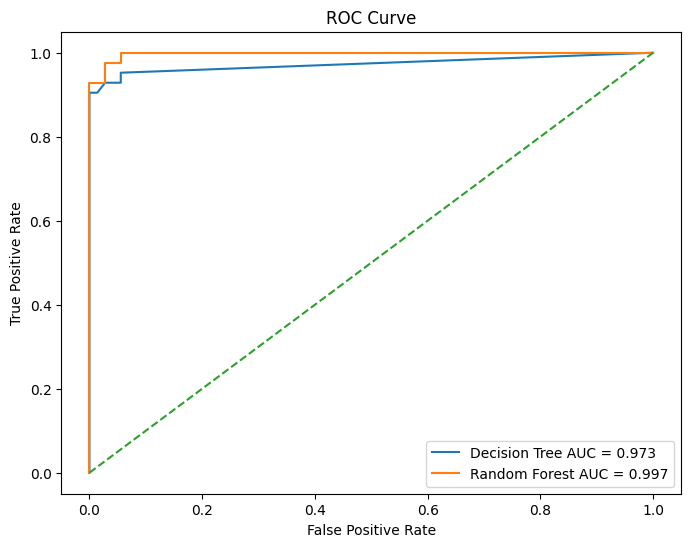

In [ ]:
dt_fpr, dt_tpr, _ = roc_curve(y_test, best_dt_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, best_rf_prob)

plt.figure(figsize=(8,6))

plt.plot(
    dt_fpr, dt_tpr,
    label=f"Decision Tree AUC = {roc_auc_score(y_test, best_dt_prob):.3f}"
)

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest AUC = {roc_auc_score(y_test, best_rf_prob):.3f}"
)

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

**CELL 32 — Precision-Recall Curve**

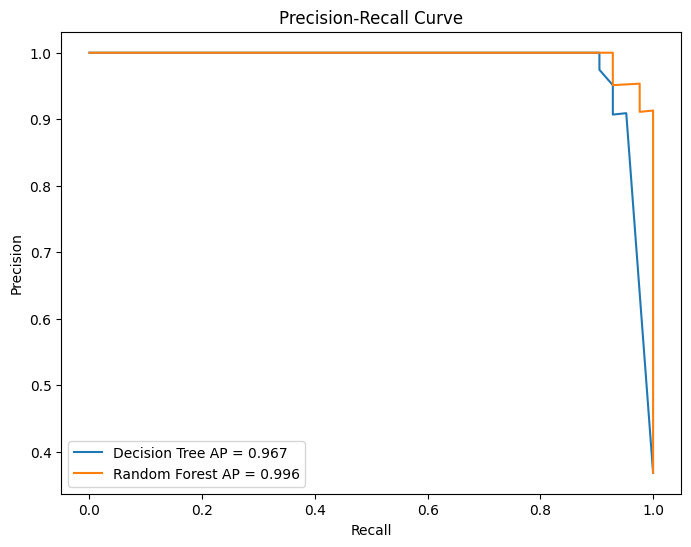

In [ ]:
dt_precision, dt_recall, _ = precision_recall_curve(
    y_test, best_dt_prob
)

rf_precision, rf_recall, _ = precision_recall_curve(
    y_test, best_rf_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    dt_recall,
    dt_precision,
    label=f"Decision Tree AP = {average_precision_score(y_test, best_dt_prob):.3f}"
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest AP = {average_precision_score(y_test, best_rf_prob):.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

**CELL 33 — Random Forest Feature Importance**

In [ ]:
importance = pd.Series(
    best_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

perimeter_worst            0.154425
area_worst                 0.140039
concave points_worst       0.106291
concave points_mean        0.098939
radius_worst               0.066967
perimeter_mean             0.062666
concavity_mean             0.056038
radius_mean                0.050489
concavity_worst            0.037472
area_mean                  0.037088
area_se                    0.030174
texture_worst              0.018503
compactness_mean           0.016061
compactness_worst          0.015759
smoothness_worst           0.014508
texture_mean               0.013520
radius_se                  0.010875
symmetry_worst             0.009967
perimeter_se               0.007551
smoothness_mean            0.007498
concavity_se               0.006308
fractal_dimension_worst    0.006056
texture_se                 0.005682
symmetry_mean              0.004717
fractal_dimension_mean     0.004495
symmetry_se                0.004260
compactness_se             0.004194
smoothness_se              0

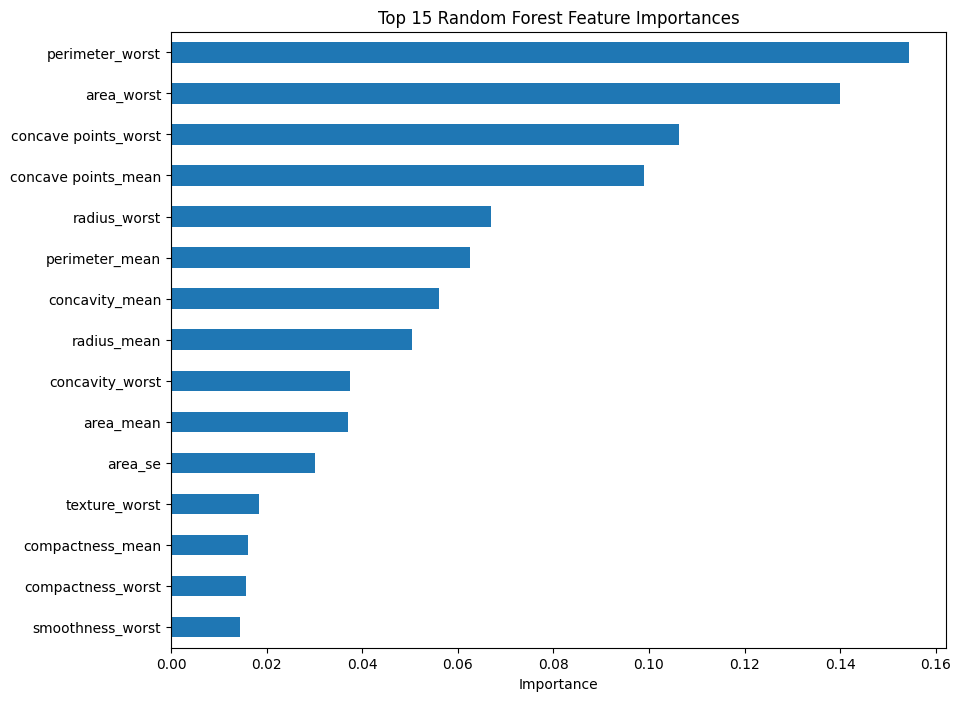

In [ ]:
plt.figure(figsize=(10,8))

importance.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.show()

**CELL 34 — Decision Tree Feature Importance**

In [ ]:
dt_importance = pd.Series(
    best_dt.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(dt_importance)

perimeter_worst            0.658577
concave points_worst       0.112237
concave points_mean        0.084739
texture_worst              0.070518
area_se                    0.048434
area_worst                 0.020424
smoothness_mean            0.005070
area_mean                  0.000000
symmetry_mean              0.000000
concavity_mean             0.000000
compactness_mean           0.000000
perimeter_mean             0.000000
texture_mean               0.000000
radius_mean                0.000000
perimeter_se               0.000000
texture_se                 0.000000
radius_se                  0.000000
fractal_dimension_mean     0.000000
concave points_se          0.000000
smoothness_se              0.000000
concavity_se               0.000000
compactness_se             0.000000
radius_worst               0.000000
fractal_dimension_se       0.000000
symmetry_se                0.000000
smoothness_worst           0.000000
compactness_worst          0.000000
concavity_worst            0

**CELL 35 — Compare the important features**

In [ ]:
feature_compare = pd.DataFrame({
    "Decision Tree": best_dt.feature_importances_,
    "Random Forest": best_rf.feature_importances_
}, index=X.columns)

feature_compare = feature_compare.sort_values(
    "Random Forest",
    ascending=False
)

feature_compare.head(15)

,Decision Tree,Random Forest
perimeter_worst,0.658577,0.154425
area_worst,0.020424,0.140039
concave points_worst,0.112237,0.106291
concave points_mean,0.084739,0.098939
radius_worst,0.000000,0.066967
perimeter_mean,0.000000,0.062666
concavity_mean,0.000000,0.056038
radius_mean,0.000000,0.050489
concavity_worst,0.000000,0.037472
area_mean,0.000000,0.037088


**CELL 36 — Final Random Forest confusion matrix**

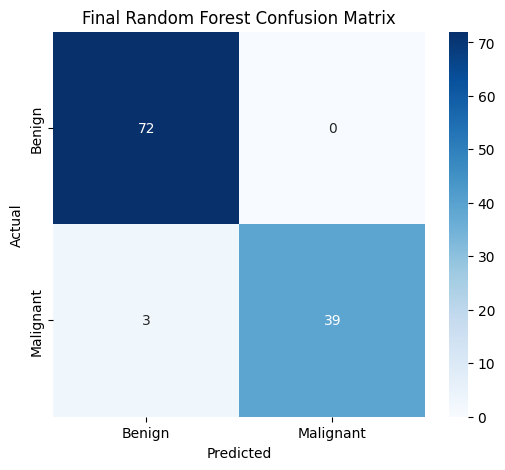

In [ ]:
cm = confusion_matrix(y_test, best_rf_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest Confusion Matrix")
plt.show()

**CELL 37 — Final classification report**

In [ ]:
print(
    classification_report(
        y_test,
        best_rf_pred,
        target_names=["Benign", "Malignant"]
    )
)

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



**CELL 38 — Check the top features with their meaning**

In [ ]:
top_features = importance.head(10)

print("Top 10 important features:")
for feature, value in top_features.items():
    print(f"{feature:25s} : {value:.4f}")

Top 10 important features:
perimeter_worst           : 0.1544
area_worst                : 0.1400
concave points_worst      : 0.1063
concave points_mean       : 0.0989
radius_worst              : 0.0670
perimeter_mean            : 0.0627
concavity_mean            : 0.0560
radius_mean               : 0.0505
concavity_worst           : 0.0375
area_mean                 : 0.0371


**CELL 39 — Test a real Benign sample**

In [ ]:
sample_b = X[y == 0].iloc[[0]]

pred = best_rf.predict(sample_b)[0]
prob = best_rf.predict_proba(sample_b)[0]

print("Actual: BENIGN")
print("Predicted:", "MALIGNANT" if pred == 1 else "BENIGN")
print(f"Benign probability: {prob[0]:.2%}")
print(f"Malignant probability: {prob[1]:.2%}")

Actual: BENIGN
Predicted: BENIGN
Benign probability: 97.44%
Malignant probability: 2.56%


**CELL 40 — Test a real Malignant sample**

In [ ]:
sample_m = X[y == 1].iloc[[0]]

pred = best_rf.predict(sample_m)[0]
prob = best_rf.predict_proba(sample_m)[0]

print("Actual: MALIGNANT")
print("Predicted:", "MALIGNANT" if pred == 1 else "BENIGN")
print(f"Benign probability: {prob[0]:.2%}")
print(f"Malignant probability: {prob[1]:.2%}")

Actual: MALIGNANT
Predicted: MALIGNANT
Benign probability: 4.25%
Malignant probability: 95.75%


**CELL 41 — Testing of 10 random real samples**

In [ ]:
samples = X.sample(10, random_state=42)

actual = y.loc[samples.index]
predicted = best_rf.predict(samples)

result = pd.DataFrame({
    "Actual": actual.map({0: "Benign", 1: "Malignant"}),
    "Predicted": pd.Series(predicted, index=samples.index)
                    .map({0: "Benign", 1: "Malignant"})
})

display(result)

print("Accuracy on these 10 samples:",
      accuracy_score(actual, predicted))

,Actual,Predicted
204,Benign,Benign
70,Malignant,Malignant
131,Malignant,Malignant
431,Benign,Benign
540,Benign,Benign
567,Malignant,Malignant
369,Malignant,Malignant
29,Malignant,Malignant
81,Benign,Benign
477,Benign,Benign


Accuracy on these 10 samples: 1.0


**CELL 42 — Testing random values**

In [ ]:
# Enter values for a new cell nucleus
new_data = {
    "radius_mean": 19.0,
    "texture_mean": 25.0,
    "perimeter_mean": 95.0,
    "area_mean": 900.0,
    "smoothness_mean": 0.40,
    "compactness_mean": 0.21,
    "concavity_mean": 0.2,
    "concave points_mean": 0.01,
    "symmetry_mean": 0.15,
    "fractal_dimension_mean": 0.04,

    "radius_se": 0.8,
    "texture_se": 4.0,
    "perimeter_se": 5.0,
    "area_se": 58.0,
    "smoothness_se": 0.012,
    "compactness_se": 0.13,
    "concavity_se": 0.07,
    "concave points_se": 0.36,
    "symmetry_se": 0.34,
    "fractal_dimension_se": 0.007,

    "radius_worst": 19.0,
    "texture_worst": 27.0,
    "perimeter_worst": 130.0,
    "area_worst": 570.0,
    "smoothness_worst": 0.23,
    "compactness_worst": 0.30,
    "concavity_worst": 0.30,
    "concave points_worst": 0.17,
    "symmetry_worst": 0.27,
    "fractal_dimension_worst": 0.8
}

# Convert to DataFrame in the same feature order
new_sample = pd.DataFrame([new_data])[X.columns]

# Prediction
prediction = best_rf.predict(new_sample)[0]
probability = best_rf.predict_proba(new_sample)[0]

if prediction == 1:
    print("Prediction: MALIGNANT")
else:
    print("Prediction: BENIGN")

print(f"Benign probability: {probability[0]:.2%}")
print(f"Malignant probability: {probability[1]:.2%}")

Prediction: MALIGNANT
Benign probability: 30.31%
Malignant probability: 69.69%
